# 05. Promotion effect: what do promos do to sales?

Rossmann runs promotions, and the business question is how much they lift sales. This notebook
estimates that lift three ways, and is explicit about how far each can be trusted.

**Important:** these are *associations under stated assumptions*, not proven causal effects. The
retailer chooses when to run promos; nothing here is a randomised experiment.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


## 1. First, what does the promo calendar look like?

If different stores promoted on different days, we could compare promoting and non-promoting
stores on the same day. Does the data allow that?

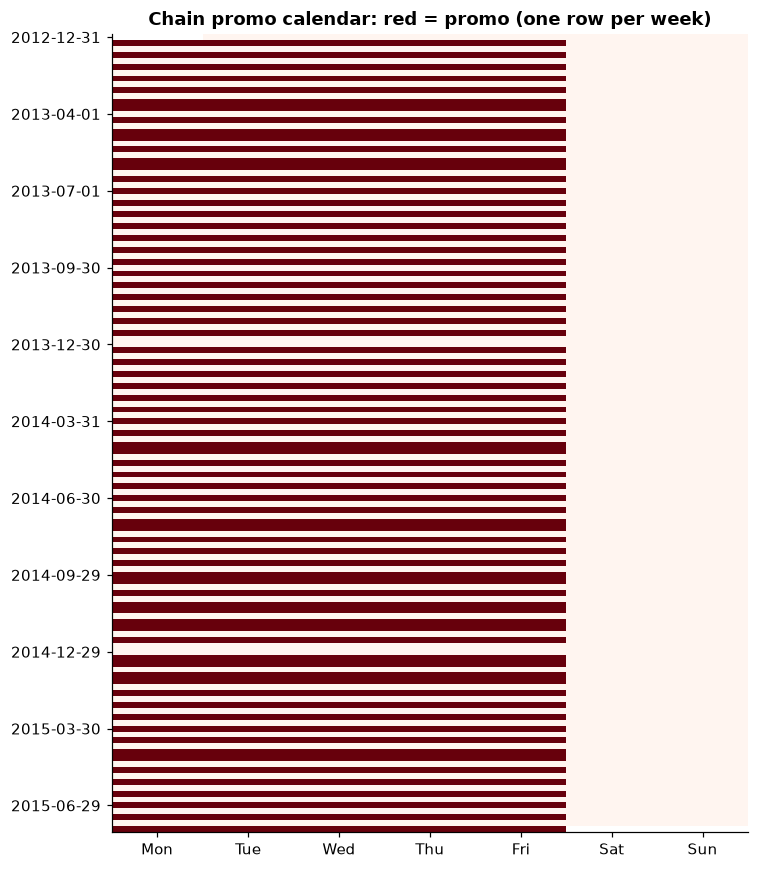

Promo weeks: 72 of 135
Share of stores following the chain calendar on a given day: min 83.9%, median 100.0%


In [2]:
promo = panel.promo
chain = (promo.mean(axis=1) > 0.5).astype(int)
weekly = pd.DataFrame({"promo": chain})
weekly["week"] = weekly.index.to_period("W-SUN").start_time
weekly["dow"] = weekly.index.dayofweek
grid = weekly.pivot_table(index="week", columns="dow", values="promo")
fig, ax = plt.subplots(figsize=(7, 8))
ax.imshow(grid.values, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ticks = list(range(0, len(grid), 13))
ax.set_yticks(ticks, [str(grid.index[i].date()) for i in ticks])
ax.set_title("Chain promo calendar: red = promo (one row per week)")
ax.grid(False)
fig.tight_layout()
plt.show()
agree = promo.eq(chain.astype(bool), axis=0).mean(axis=1)
print(f"Promo weeks: {int(chain.groupby(weekly['week']).max().sum())} of {chain.groupby(weekly['week']).max().size}")
print(f"Share of stores following the chain calendar on a given day: min {agree.min():.1%}, median {agree.median():.1%}")

Every store runs the **same** alternate-week promo calendar (Monday to Friday, then a week off).
The small disagreement is just stores with no records in late 2014. So there is no same-day control
group: on any date, all stores are either promoting or not. A date fixed effect would absorb the
promo completely, and the effect can only be read from week-to-week alternation within stores.

## 2. The raw comparison

Average sales without promo: 5,930   with promo: 8,229   ratio - 1 = +38.8%


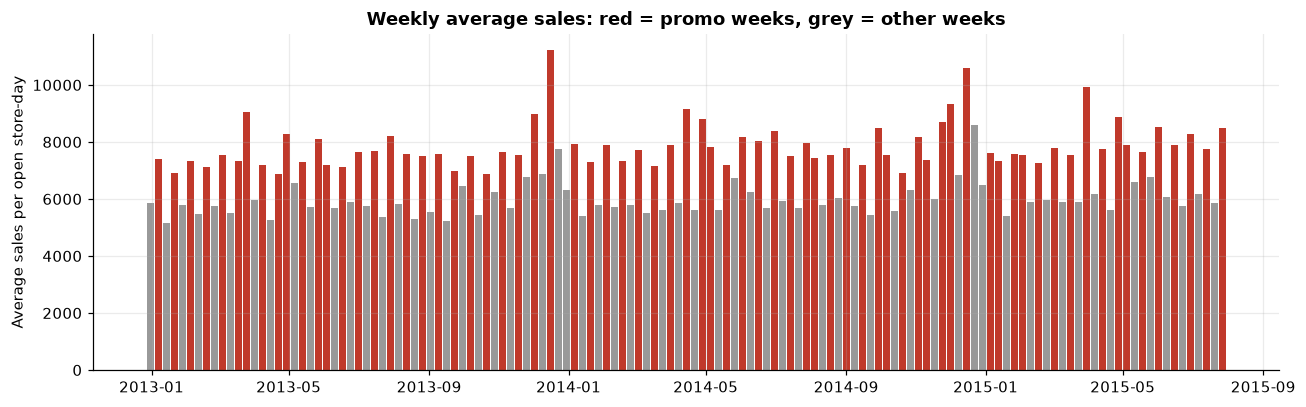

In [3]:
open_sales = panel.sales.stack().dropna().rename("sales").reset_index()
open_sales.columns = ["date", "store_id", "sales"]
open_sales["promo"] = promo.stack().reindex(pd.MultiIndex.from_frame(open_sales[["date", "store_id"]])).to_numpy()
raw = open_sales.groupby("promo")["sales"].mean()
print(f"Average sales without promo: {raw[False]:,.0f}   with promo: {raw[True]:,.0f}   ratio - 1 = {raw[True] / raw[False] - 1:+.1%}")
weekly_mean = open_sales.assign(week=open_sales["date"].dt.to_period("W-SUN").dt.start_time).groupby("week").agg(sales=("sales", "mean"), promo=("promo", "mean"))
fig, ax = plt.subplots(figsize=(12, 3.8))
colors = np.where(weekly_mean["promo"] > 0.5, COLORS["lightgbm"], "#999")
ax.bar(weekly_mean.index, weekly_mean["sales"], width=6, color=colors)
ax.set_ylabel("Average sales per open store-day")
ax.set_title("Weekly average sales: red = promo weeks, grey = other weeks")
fig.tight_layout()
plt.show()

Promo weeks (red) are visibly higher than the weeks on either side. The raw ratio mixes the promo
effect with anything else that differs between promo and non-promo days, such as the mix of weekdays
(promos run Monday to Friday and never on Sunday).

## 3. Regression with fixed effects

Compare each store only with *itself on the same weekday in the same month*: the model has
a separate baseline for each store and weekday, one for each calendar month, and controls for
holidays. The remaining difference between promo and non-promo days is the estimate. Standard
errors are clustered by calendar week, the level at which the promo actually varies.

In [4]:
from rossmann_forecast.promo import fixed_effects_lift

fe = fixed_effects_lift(panel, n_perm=60)
print(f"Lift on promo days: {fe['lift_pct']:+.1f}%   95% interval {fe['ci95_low_pct']:+.1f}% to {fe['ci95_high_pct']:+.1f}%")
print(f"Raw ratio: {fe['naive_ratio_lift_pct']:+.1f}%   (calendar weeks used for clustering: {fe['n_week_clusters']})")

Lift on promo days: +39.2%   95% interval +36.6% to +41.9%
Raw ratio: +38.8%   (calendar weeks used for clustering: 135)


### Randomisation check

If the promo weeks were unrelated to sales, shuffling which weeks are promo weeks (within a month)
should give an effect near zero. The histogram shows what shuffling produces next to the real
estimate.

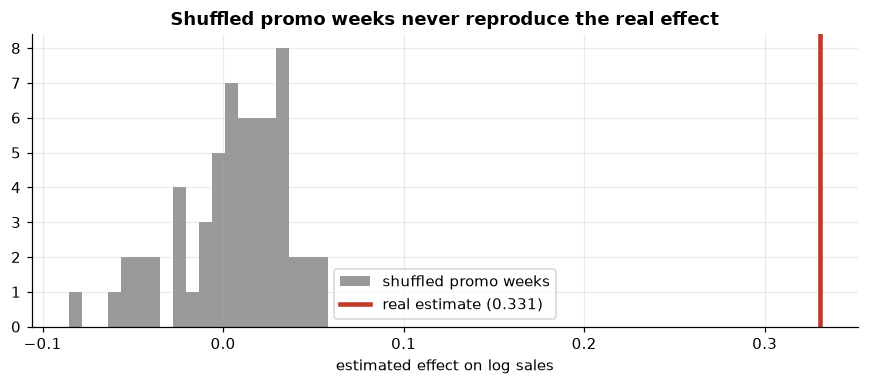

randomisation p-value (60 permutations): 0.016


In [5]:
from rossmann_forecast.promo import _demean, _week_permutation

sales = panel.sales
d_idx, s_idx = np.nonzero(sales.notna().to_numpy())
y = np.log(sales.to_numpy()[d_idx, s_idx])
dates = sales.index
month_id = ((dates.year - dates.year.min()) * 12 + dates.month - 1).to_numpy()
groups = [s_idx * 7 + dates.dayofweek.to_numpy()[d_idx], month_id[d_idx]]
n_groups = [sales.shape[1] * 7, int(month_id.max()) + 1]
y_t = _demean(y, groups, n_groups)
promo_arr = panel.promo.to_numpy()
rng = np.random.default_rng(42)
perm = []
for _ in range(60):
    mapping = _week_permutation(dates, rng)
    x_t = _demean(promo_arr[mapping[d_idx], s_idx].astype(float), groups, n_groups)
    perm.append(float(np.sum(x_t * y_t) / np.sum(x_t * x_t)))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(perm, bins=20, color="#999", label="shuffled promo weeks")
ax.axvline(fe["beta_log"], color=COLORS["lightgbm"], lw=3, label=f"real estimate ({fe['beta_log']:.3f})")
ax.set_xlabel("estimated effect on log sales")
ax.set_title("Shuffled promo weeks never reproduce the real effect")
ax.legend()
fig.tight_layout()
plt.show()
print(f"randomisation p-value from the 100 permutations in the full pipeline: {fe['permutation_p_value']:.3f}" if fe["n_permutations"] == 100 else f"randomisation p-value ({fe['n_permutations']} permutations): {fe['permutation_p_value']:.3f}")

This check shows the estimate is not what random promo weeks would produce. It cannot rule out a
confounder that alternates with the promo (for example something tied to a two-week rhythm).

## 4. Model-based "what if" for one store

The global LightGBM model can be asked: for the promo days in the forecast window, what would
sales have been **with** the promo and **without** it? Only the promo flag is flipped; the
neighbouring-day promo features stay as they were, so this is not an independent check on the
regression and tends to give a smaller number.

Chain-wide model what-if lift on promo days: +27.2%  (about 1,806 extra sales per promo day, 3 promo weeks)


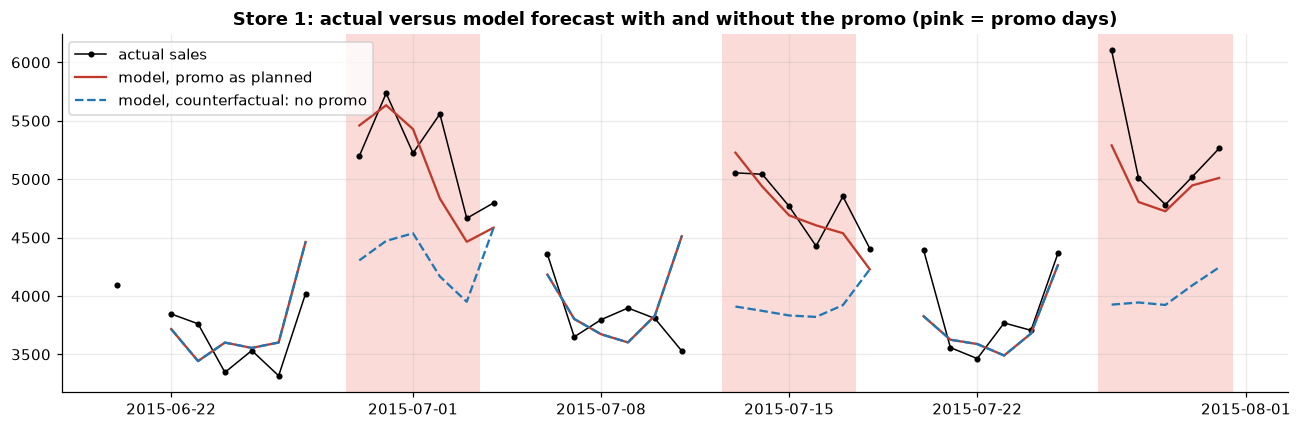

In [6]:
from rossmann_forecast.features import build_features
from rossmann_forecast.models import fit_lightgbm, forecast_rows, training_rows
from rossmann_forecast.promo import model_counterfactual

origin = final_fold.test_start
feats = build_features(panel, MIN_LAG, known_until=origin)
model = fit_lightgbm(training_rows(feats, origin))
test = forecast_rows(feats, origin, final_fold.test_end)
test = test[test["sales"].notna()]
cf = model_counterfactual(model, test)
print(f"Chain-wide model what-if lift on promo days: {cf['lift_pct']:+.1f}%  "
      f"(about {cf['mean_extra_sales_per_promo_day']:,.0f} extra sales per promo day, {cf['n_promo_weeks']} promo weeks)")

store_id = 1
g = test[test["store_id"] == store_id].copy()
g_off = g.copy()
g_off["promo"] = 0.0  # on non-promo days this changes nothing
g["with_promo"], g["without_promo"] = model.predict(g), model.predict(g_off)
g = g.set_index("date").reindex(pd.date_range(origin, final_fold.test_end))
fig, ax = plt.subplots(figsize=(12, 4))
promo_days = panel.promo[store_id].loc[g.index]
for d in g.index[promo_days.to_numpy()]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="#fadbd8", lw=0)
ax.plot(g.index, g["sales"], "o-", color="black", ms=3, lw=1, label="actual sales")
ax.plot(g.index, g["with_promo"], color=COLORS["lightgbm"], label="model, promo as planned")
ax.plot(g.index, g["without_promo"], color="#1f77b4", ls="--", label="model, counterfactual: no promo")
ax.set_title(f"Store {store_id}: actual versus model forecast with and without the promo (pink = promo days)")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Side by side

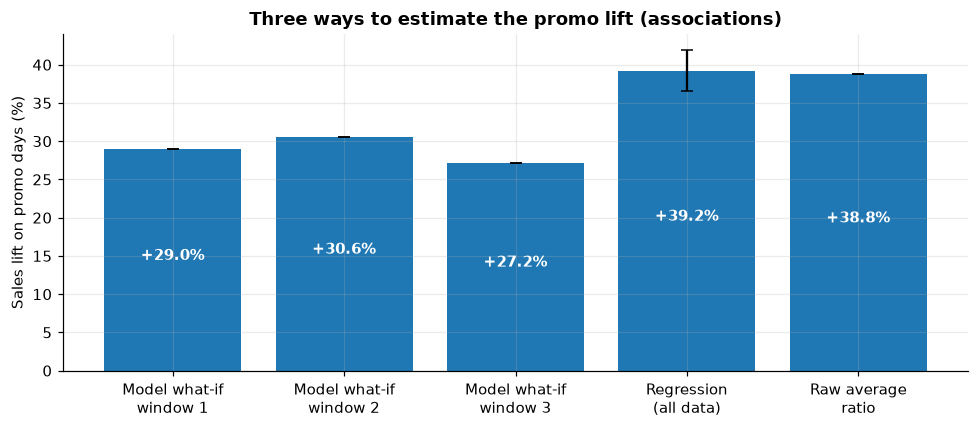

In [7]:
import json

results = json.loads((ROOT / "reports" / "results.json").read_text())
cfs = results["promo_model_counterfactual"]
labels = [f"Model what-if\nwindow {r['fold']}" for r in cfs] + ["Regression\n(all data)", "Raw average\nratio"]
vals = [r["lift_pct"] for r in cfs] + [fe["lift_pct"], fe["naive_ratio_lift_pct"]]
lower = [0] * len(cfs) + [fe["lift_pct"] - fe["ci95_low_pct"], 0]
upper = [0] * len(cfs) + [fe["ci95_high_pct"] - fe["lift_pct"], 0]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(labels, vals, yerr=[lower, upper], capsize=4, color="#1f77b4")
for i, v in enumerate(vals):
    ax.text(i, v / 2, f"{v:+.1f}%", ha="center", color="white", fontweight="bold")
ax.set_ylabel("Sales lift on promo days (%)")
ax.set_title("Three ways to estimate the promo lift (associations)")
fig.tight_layout()
plt.show()

**Reading it:** promo days sell more than comparable non-promo days: about 27% to 31% in the model what-if and
about 39% in the regression (a raw average gives 39% too). The model what-if is lower because of how it is built, and none of these is a proven
causal effect. Assumptions behind the regression: within a month, which weeks are promo weeks is
unrelated to other demand drivers; stores do not promote on their own schedules; stockpiling and
post-promo dips are not modelled; customer counts are not controlled for, because they are a
consequence of the promo.